# Task 1: Dataset Understanding

## Objective
Load the UCI Online Retail dataset and examine its structure,
data types, sample records, and descriptive statistics.

The analysis uses transactions from 1 September 2011
through 30 November 2011 (inclusive), across all countries.

This original subset will remain unchanged for Tasks 1 and 2.

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import requests
from io import BytesIO

# Dataset hosted on GitHub
DATA_URL = (
    "https://raw.githubusercontent.com/"
    "2026em1100040-pixel/DPP_Assignment_1/"
    "main/Online%20Retail.xlsx"
)

# Download dataset automatically
response = requests.get(DATA_URL, timeout=120)
response.raise_for_status()

# Read Excel file
df = pd.read_excel(
    BytesIO(response.content),
    engine="openpyxl"
)

# Convert date column
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

# Filter September to November 2011
mask = (
    (df["InvoiceDate"] >= "2011-09-01") &
    (df["InvoiceDate"] < "2011-12-01")
)

df_baseline = df.loc[mask].copy()

print("Original dataset shape:", df.shape)
print("Baseline dataset shape:", df_baseline.shape)

print("\nDate range:")
print(df_baseline["InvoiceDate"].min())
print(df_baseline["InvoiceDate"].max())

display(df_baseline.head())


Original dataset shape: (541909, 8)
Baseline dataset shape: (195679, 8)

Date range:
2011-09-01 08:25:00
2011-11-30 17:42:00


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
320705,565080,20677,PINK POLKADOT BOWL,8,2011-09-01 08:25:00,1.25,13509.0,United Kingdom
320706,565080,22128,PARTY CONES CANDY ASSORTED,24,2011-09-01 08:25:00,1.25,13509.0,United Kingdom
320707,565081,21067,NaN,1,2011-09-01 09:03:00,0.00,NaN,United Kingdom
320708,565082,22423,REGENCY CAKESTAND 3 TIER,2,2011-09-01 09:15:00,12.75,13305.0,United Kingdom
320709,565082,15060B,FAIRY CAKE DESIGN UMBRELLA,8,2011-09-01 09:15:00,3.75,13305.0,United Kingdom


### 1.2 Dataset Structure and Descriptive Statistics

We examine column names, inferred data types, the first five
records, and descriptive statistics to understand the dataset
before assessing data quality.

In [2]:

# Dataset dimensions
print("Rows and columns:", df_baseline.shape)

# Column names
print("\nColumn names:")
print(df_baseline.columns.tolist())

# Data types and non-null counts
print("\nDataset information:")
df_baseline.info()

# First five records
print("\nFirst five rows:")
display(df_baseline.head())

# Descriptive statistics for all columns
print("\nDescriptive statistics:")
display(df_baseline.describe(include="all").T)


Rows and columns: (195679, 8)

Column names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
Index: 195679 entries, 320705 to 516383
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    195679 non-null  object        
 1   StockCode    195679 non-null  object        
 2   Description  195401 non-null  object        
 3   Quantity     195679 non-null  int64         
 4   InvoiceDate  195679 non-null  datetime64[ns]
 5   UnitPrice    195679 non-null  float64       
 6   CustomerID   157115 non-null  float64       
 7   Country      195679 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 13.4+ MB

First five rows:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
320705,565080,20677,PINK POLKADOT BOWL,8,2011-09-01 08:25:00,1.25,13509.0,United Kingdom
320706,565080,22128,PARTY CONES CANDY ASSORTED,24,2011-09-01 08:25:00,1.25,13509.0,United Kingdom
320707,565081,21067,NaN,1,2011-09-01 09:03:00,0.00,NaN,United Kingdom
320708,565082,22423,REGENCY CAKESTAND 3 TIER,2,2011-09-01 09:15:00,12.75,13305.0,United Kingdom
320709,565082,15060B,FAIRY CAKE DESIGN UMBRELLA,8,2011-09-01 09:15:00,3.75,13305.0,United Kingdom



Descriptive statistics:


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
InvoiceNo,195679.0,8426.0,573585.0,1114.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
StockCode,195679.0,3280.0,22086.0,812.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,195401,3358,PAPER CHAIN KIT 50'S CHRISTMAS,812,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,195679.0,NaN,NaN,NaN,9.508608,-4830.0,1.0,3.0,11.0,12540.0,51.68751
InvoiceDate,195679,NaN,NaN,NaN,2011-10-22 17:23:52.712145664,2011-09-01 08:25:00,2011-09-30 11:05:00,2011-10-25 15:21:00,2011-11-14 15:37:00,2011-11-30 17:42:00,NaN
UnitPrice,195679.0,NaN,NaN,NaN,4.0363,0.0,1.25,2.08,4.13,8286.22,48.88006
CustomerID,157115.0,NaN,NaN,NaN,15294.675951,12347.0,14049.0,15154.0,16753.0,18287.0,1692.017797
Country,195679,30,United Kingdom,178694,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [3]:

field_types = pd.DataFrame({
    "Column": [
        "InvoiceNo", "StockCode", "Description",
        "Quantity", "InvoiceDate", "UnitPrice",
        "CustomerID", "Country"
    ],
    "Field Type": [
        "Identifier", "Identifier", "Categorical",
        "Numeric", "Date/Time", "Numeric",
        "Identifier", "Categorical"
    ]
})

display(field_types)


,Column,Field Type
0,InvoiceNo,Identifier
1,StockCode,Identifier
2,Description,Categorical
3,Quantity,Numeric
4,InvoiceDate,Date/Time
5,UnitPrice,Numeric
6,CustomerID,Identifier
7,Country,Categorical


## Task 2: Data Quality Assessment

### 2.1 Missing Value Analysis

Missing values can affect customer identification, transaction
aggregation, and the accuracy of customer-level features.

We examine missing values in each column and calculate their
percentage within the baseline dataset.

No records are removed at this stage.

,Missing Count,Missing Percentage (%)
CustomerID,38564,19.71
Description,278,0.14
StockCode,0,0.00
InvoiceNo,0,0.00
Quantity,0,0.00
InvoiceDate,0,0.00
UnitPrice,0,0.00
Country,0,0.00


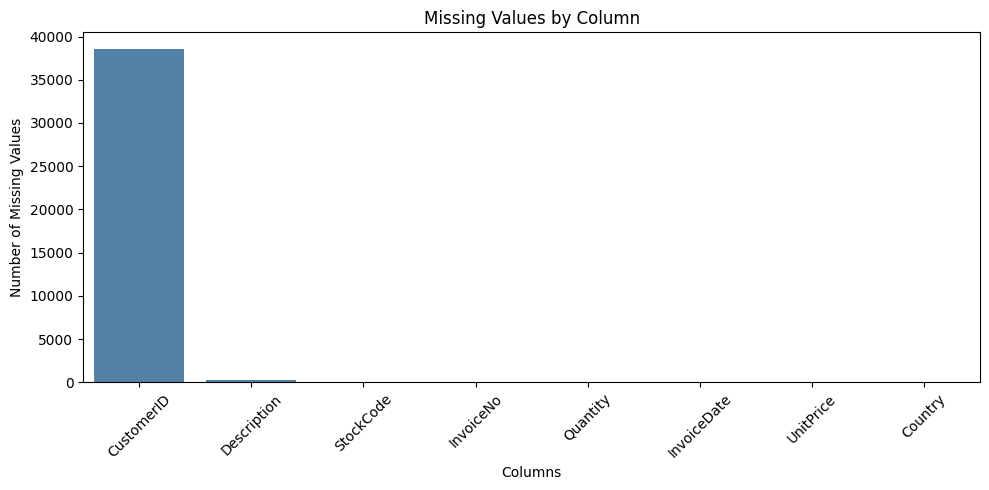

In [4]:

# Missing value assessment
missing_summary = pd.DataFrame({
    "Missing Count": df_baseline.isnull().sum(),
    "Missing Percentage (%)": (
        df_baseline.isnull().mean() * 100
    ).round(2)
})

missing_summary = missing_summary.sort_values(
    by="Missing Count", ascending=False
)

display(missing_summary)

# Visualize missing values
plt.figure(figsize=(10, 5))

sns.barplot(
    x=missing_summary.index,
    y=missing_summary["Missing Count"],
    color="steelblue"
)

plt.title("Missing Values by Column")
plt.xlabel("Columns")
plt.ylabel("Number of Missing Values")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


### 2.2 Duplicate Row Assessment

Exact duplicate rows may indicate repeated transaction records
and could inflate customer spending and purchase quantities.

We identify and count exact duplicates without removing them.
Duplicate removal decisions will be addressed in Task 3.

In [5]:

# Identify exact duplicate rows
duplicate_mask = df_baseline.duplicated()

# Count duplicates
duplicate_count = duplicate_mask.sum()

print("Total baseline rows:", len(df_baseline))
print("Exact duplicate rows:", duplicate_count)
print("Duplicate percentage:",
      round(duplicate_count / len(df_baseline) * 100, 2), "%")

# Display sample duplicate records
print("\nSample duplicate records:")
display(df_baseline.loc[duplicate_mask].head(10))


Total baseline rows: 195679
Exact duplicate rows: 2506
Duplicate percentage: 1.28 %

Sample duplicate records:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
321238,565141,20726,LUNCH BAG WOODLAND,1,2011-09-01 13:40:00,1.65,17841.0,United Kingdom
321241,565141,20726,LUNCH BAG WOODLAND,1,2011-09-01 13:40:00,1.65,17841.0,United Kingdom
321242,565141,20725,LUNCH BAG RED RETROSPOT,1,2011-09-01 13:40:00,1.65,17841.0,United Kingdom
321268,565141,21976,PACK OF 60 MUSHROOM CAKE CASES,1,2011-09-01 13:40:00,0.55,17841.0,United Kingdom
321278,565141,22978,PANTRY ROLLING PIN,1,2011-09-01 13:40:00,3.75,17841.0,United Kingdom
321535,565151,22979,PANTRY WASHING UP BRUSH,1,2011-09-01 14:29:00,1.45,16923.0,United Kingdom
321613,565152,22208,WOOD STAMP SET THANK YOU,1,2011-09-01 14:42:00,0.83,17799.0,United Kingdom
323341,565289,21755,LOVE BUILDING BLOCK WORD,3,2011-09-02 11:43:00,5.95,14911.0,EIRE
323444,565303,21558,SKULL LUNCH BOX WITH CUTLERY,1,2011-09-02 12:17:00,2.55,NaN,Unspecified
323617,565324,22910,PAPER CHAIN KIT VINTAGE CHRISTMAS,1,2011-09-02 13:18:00,2.95,13232.0,United Kingdom


### 2.3 Inconsistent Text Values

Text inconsistencies, including extra whitespace and inconsistent
capitalization, can create artificial categories and affect product
variety calculations.

We identify these inconsistencies without modifying the baseline.
Corrections will be performed in Task 3.

In [6]:

# Identify inconsistent text values
text_columns = [
    "Description", "Country", "StockCode", "InvoiceNo"
]

text_issues = []

for col in text_columns:
    values = df_baseline[col].dropna().astype(str)

    whitespace_count = (
        values != values.str.strip()
    ).sum()

    normalized = values.str.strip().str.upper()

    case_variants = (
        pd.DataFrame({
            "original": values,
            "normalized": normalized
        })
        .groupby("normalized")["original"]
        .nunique()
    )

    case_variant_groups = (case_variants > 1).sum()

    text_issues.append({
        "Column": col,
        "Whitespace Issues": whitespace_count,
        "Case Variant Groups": case_variant_groups
    })

text_issues_df = pd.DataFrame(text_issues)

display(text_issues_df)

# Show examples of descriptions with extra whitespace
description = df_baseline["Description"].dropna()

print("Examples of descriptions with whitespace:")
display(
    description[
        description != description.str.strip()
    ].head(10)
)

,Column,Whitespace Issues,Case Variant Groups
0,Description,45433,13
1,Country,0,0
2,StockCode,0,67
3,InvoiceNo,0,0


Examples of descriptions with whitespace:


,Description
320718,BUTTON BOX
320720,CLAM SHELL SMALL
320722,SET OF 60 I LOVE LONDON CAKE CASES
320724,SOLDIERS EGG CUP
320727,PACK OF 12 LONDON TISSUES
320728,TOADSTOOL BEDSIDE LIGHT
320730,ANTIQUE SILVER BAUBLE LAMP
320748,VINTAGE CHRISTMAS GIFT BAG LARGE
320749,50'S CHRISTMAS GIFT BAG LARGE
320750,6 GIFT TAGS 50'S CHRISTMAS


### 2.4 Data Type Mismatch Assessment

Incorrect data types can affect calculations, date filtering,
and customer-level aggregation.

We check the inferred data types and identify values that
cannot be converted to their expected types.

CustomerID, InvoiceNo, and StockCode are identifiers,
not numerical features.

In [7]:

# Expected data types
expected_types = {
    "InvoiceNo": "Identifier",
    "StockCode": "Identifier",
    "Description": "Text",
    "Quantity": "Numeric",
    "InvoiceDate": "Datetime",
    "UnitPrice": "Numeric",
    "CustomerID": "Identifier",
    "Country": "Text"
}

type_results = []

for col, expected in expected_types.items():
    actual = str(df_baseline[col].dtype)

    if expected == "Numeric":
        invalid_count = (
            pd.to_numeric(df_baseline[col], errors="coerce").isna()
            & df_baseline[col].notna()
        ).sum()

    elif expected == "Datetime":
        invalid_count = (
            pd.to_datetime(df_baseline[col], errors="coerce").isna()
            & df_baseline[col].notna()
        ).sum()

    else:
        invalid_count = 0

    type_results.append({
        "Column": col,
        "Expected Type": expected,
        "Actual Type": actual,
        "Invalid Values": int(invalid_count)
    })

type_summary = pd.DataFrame(type_results)

display(type_summary)

,Column,Expected Type,Actual Type,Invalid Values
0,InvoiceNo,Identifier,object,0
1,StockCode,Identifier,object,0
2,Description,Text,object,0
3,Quantity,Numeric,int64,0
4,InvoiceDate,Datetime,datetime64[ns],0
5,UnitPrice,Numeric,float64,0
6,CustomerID,Identifier,float64,0
7,Country,Text,object,0


### 2.5 Outlier Detection Using IQR

The Interquartile Range (IQR) method identifies potential
outliers in Quantity and UnitPrice.

IQR = Q3 - Q1

Lower Bound = Q1 - 1.5 × IQR
Upper Bound = Q3 + 1.5 × IQR

Values outside these bounds are flagged as potential outliers.

Extreme values may represent genuine bulk purchases or
expensive products, so they are not automatically removed.

The baseline dataset remains unchanged.

,Field,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
0,Quantity,-14.00,26.00,10471,5.35
1,UnitPrice,-3.07,8.45,12151,6.21


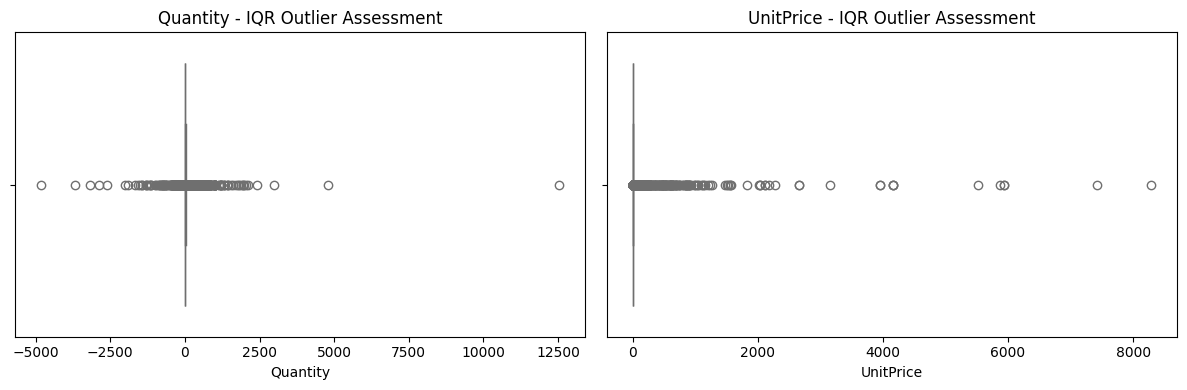

In [8]:

# Detect potential outliers using IQR
outlier_results = []

for col in ["Quantity", "UnitPrice"]:
    Q1 = df_baseline[col].quantile(0.25)
    Q3 = df_baseline[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outlier_mask = (
        (df_baseline[col] < lower) |
        (df_baseline[col] > upper)
    )

    outlier_results.append({
        "Field": col,
        "Lower Bound": round(lower, 2),
        "Upper Bound": round(upper, 2),
        "Outlier Count": int(outlier_mask.sum()),
        "Outlier Percentage": round(
            outlier_mask.mean() * 100, 2
        )
    })

outlier_summary = pd.DataFrame(outlier_results)
display(outlier_summary)

# Visualize distributions and potential outliers
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, col in zip(axes, ["Quantity", "UnitPrice"]):
    sns.boxplot(
        x=df_baseline[col],
        ax=ax,
        color="skyblue"
    )
    ax.set_title(f"{col} - IQR Outlier Assessment")
    ax.set_xlabel(col)

plt.tight_layout()
plt.show()


### 2.6 Cancellations and Non-Positive Transactions

We identify:
1. Cancelled invoices (InvoiceNo beginning with C).
2. Transactions with Quantity <= 0.
3. Transactions with UnitPrice <= 0.

These categories may overlap. Therefore, their individual counts
should not be added together to calculate total affected rows.

No records are removed during this assessment.

In [9]:

# Identify transaction issues
cancel_mask = (
    df_baseline["InvoiceNo"]
    .astype(str)
    .str.upper()
    .str.startswith("C")
)

quantity_mask = df_baseline["Quantity"] <= 0
price_mask = df_baseline["UnitPrice"] <= 0

# Count issues separately
issue_counts = pd.DataFrame({
    "Issue": [
        "Cancelled invoice lines",
        "Non-positive Quantity",
        "Non-positive UnitPrice",
        "Any of the above (unique rows)"
    ],
    "Count": [
        int(cancel_mask.sum()),
        int(quantity_mask.sum()),
        int(price_mask.sum()),
        int((cancel_mask | quantity_mask | price_mask).sum())
    ]
})

display(issue_counts)

# Count overlapping conditions
overlap_summary = pd.DataFrame({
    "Overlap": [
        "Cancellation and non-positive Quantity",
        "Cancellation and non-positive UnitPrice",
        "Non-positive Quantity and UnitPrice",
        "All three conditions"
    ],
    "Count": [
        int((cancel_mask & quantity_mask).sum()),
        int((cancel_mask & price_mask).sum()),
        int((quantity_mask & price_mask).sum()),
        int((cancel_mask & quantity_mask & price_mask).sum())
    ]
})

display(overlap_summary)


,Issue,Count
0,Cancelled invoice lines,3081
1,Non-positive Quantity,3462
2,Non-positive UnitPrice,664
3,Any of the above (unique rows),3745


,Overlap,Count
0,Cancellation and non-positive Quantity,3081
1,Cancellation and non-positive UnitPrice,0
2,Non-positive Quantity and UnitPrice,381
3,All three conditions,0


### 2.7 Data Quality Assessment Summary

The following table summarizes the data quality issues identified
in the original September–November 2011 baseline dataset.

It includes the affected fields, issue counts, and potential
impacts on customer profiling.

Counts may overlap because a single transaction can have
multiple data quality issues.

All cleaning decisions will be implemented in Task 3.

In [10]:

# Consolidated data quality summary
quality_summary = pd.DataFrame([
    {
        "Issue": "Missing values",
        "Field": "CustomerID",
        "Count": int(df_baseline["CustomerID"].isna().sum()),
        "Potential impact": "Cannot reliably identify customers"
    },
    {
        "Issue": "Missing values",
        "Field": "Description",
        "Count": int(df_baseline["Description"].isna().sum()),
        "Potential impact": "Reduced product interpretability"
    },
    {
        "Issue": "Exact duplicates",
        "Field": "All columns",
        "Count": int(duplicate_count),
        "Potential impact": "May inflate spending and quantities"
    },
    {
        "Issue": "Extra whitespace",
        "Field": "Description",
        "Count": int(
            text_issues_df.loc[
                text_issues_df["Column"] == "Description",
                "Whitespace Issues"
            ].iloc[0]
        ),
        "Potential impact": "Inconsistent product descriptions"
    },
    {
        "Issue": "Invalid numeric/date values",
        "Field": "Quantity, UnitPrice, InvoiceDate",
        "Count": int(type_summary["Invalid Values"].sum()),
        "Potential impact": "May affect calculations and date analysis"
    },
    {
        "Issue": "Quantity outliers (IQR)",
        "Field": "Quantity",
        "Count": int(outlier_summary.loc[
            outlier_summary["Field"] == "Quantity",
            "Outlier Count"
        ].iloc[0]),
        "Potential impact": "Extreme quantities may distort customer profiles"
    },
    {
        "Issue": "Price outliers (IQR)",
        "Field": "UnitPrice",
        "Count": int(outlier_summary.loc[
            outlier_summary["Field"] == "UnitPrice",
            "Outlier Count"
        ].iloc[0]),
        "Potential impact": "Extreme prices may distort spending"
    },
    {
        "Issue": "Cancelled invoice lines",
        "Field": "InvoiceNo",
        "Count": int(cancel_mask.sum()),
        "Potential impact": "Returns may distort completed-sales analysis"
    },
    {
        "Issue": "Non-positive quantity",
        "Field": "Quantity",
        "Count": int(quantity_mask.sum()),
        "Potential impact": "Does not represent positive sales quantity"
    },
    {
        "Issue": "Non-positive price",
        "Field": "UnitPrice",
        "Count": int(price_mask.sum()),
        "Potential impact": "Does not represent positive sales revenue"
    }
])

display(quality_summary)


,Issue,Field,Count,Potential impact
0,Missing values,CustomerID,38564,Cannot reliably identify customers
1,Missing values,Description,278,Reduced product interpretability
2,Exact duplicates,All columns,2506,May inflate spending and quantities
3,Extra whitespace,Description,45433,Inconsistent product descriptions
4,Invalid numeric/date values,"Quantity, UnitPrice, InvoiceDate",0,May affect calculations and date analysis
5,Quantity outliers (IQR),Quantity,10471,Extreme quantities may distort customer profiles
6,Price outliers (IQR),UnitPrice,12151,Extreme prices may distort spending
7,Cancelled invoice lines,InvoiceNo,3081,Returns may distort completed-sales analysis
8,Non-positive quantity,Quantity,3462,Does not represent positive sales quantity
9,Non-positive price,UnitPrice,664,Does not represent positive sales revenue


## Task 3: Data Cleaning

### 3.1 Handling Missing Customer IDs

CustomerID is essential because the final dataset must contain
one row per identifiable customer.

Transactions with missing CustomerID cannot be reliably assigned
to a customer and will therefore be removed.

We create a separate working copy to preserve the original
baseline dataset used in Tasks 1 and 2.

Before-and-after row counts are reported to measure the impact.

In [11]:

# Create a working copy
df_clean = df_baseline.copy()

# Before cleaning
rows_before = len(df_clean)
missing_ids = df_clean["CustomerID"].isna().sum()

# Remove transactions with missing CustomerID
df_clean = df_clean.dropna(
    subset=["CustomerID"]
).copy()

# After cleaning
rows_after = len(df_clean)

# Summarize cleaning impact
cleaning_step1 = pd.DataFrame({
    "Metric": [
        "Rows before cleaning",
        "Missing CustomerID rows removed",
        "Rows after cleaning",
        "Percentage of rows retained"
    ],
    "Value": [
        rows_before,
        int(missing_ids),
        rows_after,
        round(rows_after / rows_before * 100, 2)
    ]
})

display(cleaning_step1)

# Verify no missing CustomerIDs remain
print("Remaining missing CustomerIDs:",
      df_clean["CustomerID"].isna().sum())

print("Original baseline shape:", df_baseline.shape)
print("Working dataset shape:", df_clean.shape)


,Metric,Value
0,Rows before cleaning,195679.00
1,Missing CustomerID rows removed,38564.00
2,Rows after cleaning,157115.00
3,Percentage of rows retained,80.29


Remaining missing CustomerIDs: 0
Original baseline shape: (195679, 8)
Working dataset shape: (157115, 8)


### 3.2 Removing Exact Duplicate Rows

Exact duplicate transaction records may inflate customer spending
and purchase quantities.

We remove rows where all column values are identical.

Rows sharing an InvoiceNo are not automatically duplicates,
because one invoice can contain multiple products.

Before-and-after counts are compared to measure the impact.

In [12]:

# Count rows before duplicate removal
rows_before = len(df_clean)

# Identify exact duplicates
duplicates_before = df_clean.duplicated().sum()

# Remove exact duplicate rows
df_clean = df_clean.drop_duplicates().copy()

# Count rows after cleaning
rows_after = len(df_clean)

# Summarize impact
duplicate_cleaning_summary = pd.DataFrame({
    "Metric": [
        "Rows before cleaning",
        "Exact duplicates removed",
        "Rows after cleaning",
        "Percentage of rows retained"
    ],
    "Value": [
        rows_before,
        int(duplicates_before),
        rows_after,
        round(rows_after / rows_before * 100, 2)
    ]
})

display(duplicate_cleaning_summary)

# Verify duplicate removal
print("Remaining exact duplicates:",
      df_clean.duplicated().sum())

print("Original baseline shape:", df_baseline.shape)
print("Cleaned dataset shape:", df_clean.shape)


,Metric,Value
0,Rows before cleaning,157115.00
1,Exact duplicates removed,2496.00
2,Rows after cleaning,154619.00
3,Percentage of rows retained,98.41


Remaining exact duplicates: 0
Original baseline shape: (195679, 8)
Cleaned dataset shape: (154619, 8)


### 3.3 Standardizing Text Values

Inconsistent whitespace and capitalization can create artificial
categories and affect product identification.

We standardize text fields while preserving identifier values.

Cleaning decisions:
- Description: Remove extra spaces and standardize capitalization.
- Country: Remove extra spaces.
- StockCode: Remove surrounding spaces without changing case.
- InvoiceNo: Remove surrounding spaces without changing case.

Missing descriptions are retained because product variety
will be calculated using StockCode.

Before-and-after examples and affected row counts are reported.

In [13]:

# Text columns to standardize
text_columns = ["Description", "Country", "StockCode", "InvoiceNo"]

# Preserve original values for comparison
text_before = df_clean[text_columns].copy()

# Standardize text
df_clean["Description"] = (
    df_clean["Description"]
    .astype("string")
    .str.strip()
    .str.replace(r"\s+", " ", regex=True)
    .str.upper()
)

df_clean["Country"] = (
    df_clean["Country"]
    .astype("string")
    .str.strip()
)

for col in ["StockCode", "InvoiceNo"]:
    df_clean[col] = (
        df_clean[col]
        .astype("string")
        .str.strip()
    )

# Compare before and after
text_cleaning_results = []

for col in text_columns:
    before = text_before[col].astype("string")
    after = df_clean[col].astype("string")

    changed = before.ne(after).fillna(False)

    text_cleaning_results.append({
        "Column": col,
        "Rows Modified": int(changed.sum())
    })

text_cleaning_summary = pd.DataFrame(text_cleaning_results)

display(text_cleaning_summary)

# Show examples of modified descriptions
comparison = pd.DataFrame({
    "Before": text_before["Description"],
    "After": df_clean["Description"]
})

changed_rows = (
    comparison["Before"]
    .astype("string")
    .ne(comparison["After"])
    .fillna(False)
)

print("Examples of standardized descriptions:")
display(comparison.loc[changed_rows].head(10))

# Verify row count remains unchanged
print("Rows after text cleaning:", len(df_clean))
print("Baseline rows (unchanged):", len(df_baseline))


,Column,Rows Modified
0,Description,40386
1,Country,0
2,StockCode,0
3,InvoiceNo,0


Examples of standardized descriptions:


,Before,After
320715,SET/6 PINK BUTTERFLY T-LIGHTS,SET/6 PINK BUTTERFLY T-LIGHTS
320718,BUTTON BOX,BUTTON BOX
320720,CLAM SHELL SMALL,CLAM SHELL SMALL
320721,FOUR HOOK WHITE LOVEBIRDS,FOUR HOOK WHITE LOVEBIRDS
320722,SET OF 60 I LOVE LONDON CAKE CASES,SET OF 60 I LOVE LONDON CAKE CASES
320724,SOLDIERS EGG CUP,SOLDIERS EGG CUP
320727,PACK OF 12 LONDON TISSUES,PACK OF 12 LONDON TISSUES
320728,TOADSTOOL BEDSIDE LIGHT,TOADSTOOL BEDSIDE LIGHT
320730,ANTIQUE SILVER BAUBLE LAMP,ANTIQUE SILVER BAUBLE LAMP
320748,VINTAGE CHRISTMAS GIFT BAG LARGE,VINTAGE CHRISTMAS GIFT BAG LARGE


Rows after text cleaning: 154619
Baseline rows (unchanged): 195679


### 3.4 Filtering Completed Sales

For customer profiling, only completed positive-value sales
are retained.

We exclude:
- Cancelled invoices (InvoiceNo starting with C).
- Transactions with Quantity <= 0.
- Transactions with UnitPrice <= 0.

These conditions may overlap, so a combined filter is used
to avoid double-counting removed records.

This means Total Spend will represent completed positive sales,
not net revenue after returns and refunds.

Extreme positive values are retained because they may represent
legitimate bulk purchases or high-value products.

In [14]:

# Record counts before filtering
rows_before = len(df_clean)

# Identify invalid completed-sales transactions
cancelled = (
    df_clean["InvoiceNo"]
    .astype("string")
    .str.upper()
    .str.startswith("C", na=False)
)

invalid_quantity = df_clean["Quantity"] <= 0
invalid_price = df_clean["UnitPrice"] <= 0

# Combined exclusion mask
exclude_mask = (
    cancelled |
    invalid_quantity |
    invalid_price
)

# Create completed-sales dataset
df_sales = df_clean.loc[~exclude_mask].copy()

# Summarize filtering impact
sales_summary = pd.DataFrame({
    "Metric": [
        "Rows before filtering",
        "Cancelled invoice lines",
        "Non-positive quantity lines",
        "Non-positive price lines",
        "Unique rows excluded",
        "Completed-sales rows retained",
        "Percentage retained"
    ],
    "Value": [
        rows_before,
        int(cancelled.sum()),
        int(invalid_quantity.sum()),
        int(invalid_price.sum()),
        int(exclude_mask.sum()),
        len(df_sales),
        round(len(df_sales) / rows_before * 100, 2)
    ]
})

display(sales_summary)

# Verify completed-sales conditions
print("Remaining cancellations:",
      df_sales["InvoiceNo"].str.upper().str.startswith("C").sum())

print("Non-positive quantities:",
      (df_sales["Quantity"] <= 0).sum())

print("Non-positive prices:",
      (df_sales["UnitPrice"] <= 0).sum())

print("Missing CustomerIDs:",
      df_sales["CustomerID"].isna().sum())

print("Completed-sales shape:", df_sales.shape)


,Metric,Value
0,Rows before filtering,154619.00
1,Cancelled invoice lines,2970.00
2,Non-positive quantity lines,2970.00
3,Non-positive price lines,19.00
4,Unique rows excluded,2989.00
5,Completed-sales rows retained,151630.00
6,Percentage retained,98.07


Remaining cancellations: 0
Non-positive quantities: 0
Non-positive prices: 0
Missing CustomerIDs: 0
Completed-sales shape: (151630, 8)


### 3.5 Final Cleaning Validation

Before customer-level aggregation, we verify that the cleaned
dataset contains valid customer identifiers, invoice numbers,
stock codes, dates, quantities, and prices.

This ensures that the dataset is ready for feature engineering.

In [15]:

# Required fields for customer-level aggregation
required_columns = [
    "CustomerID",
    "InvoiceNo",
    "StockCode",
    "InvoiceDate",
    "Quantity",
    "UnitPrice"
]

# Check missing values
print("Missing values in required fields:")
display(df_sales[required_columns].isna().sum())

# Validate cleaned dataset
validation = {
    "Missing required values":
        int(df_sales[required_columns].isna().sum().sum()),

    "Exact duplicates":
        int(df_sales.duplicated().sum()),

    "Cancelled invoices":
        int(
            df_sales["InvoiceNo"]
            .astype("string")
            .str.upper()
            .str.startswith("C", na=False)
            .sum()
        ),

    "Non-positive quantities":
        int((df_sales["Quantity"] <= 0).sum()),

    "Non-positive prices":
        int((df_sales["UnitPrice"] <= 0).sum())
}

validation_df = pd.DataFrame(
    validation.items(),
    columns=["Validation Check", "Remaining Issues"]
)

display(validation_df)

# Stop execution if cleaning is incomplete
assert all(value == 0 for value in validation.values()), \
    "Data cleaning validation failed."

print("All cleaning checks passed.")
print("Final cleaned dataset shape:", df_sales.shape)
print("Unique customers:", df_sales["CustomerID"].nunique())


Missing values in required fields:


,0
CustomerID,0
InvoiceNo,0
StockCode,0
InvoiceDate,0
Quantity,0
UnitPrice,0


,Validation Check,Remaining Issues
0,Missing required values,0
1,Exact duplicates,0
2,Cancelled invoices,0
3,Non-positive quantities,0
4,Non-positive prices,0


All cleaning checks passed.
Final cleaned dataset shape: (151630, 8)
Unique customers: 2851


## Task 4: Data Transformation and Aggregation

### 4.1 Customer-Level Feature Engineering

The cleaned completed-sales dataset is aggregated to create
one row per customer.

Four features are calculated:

1. Recency: Calendar days between the customer's last
   purchase and 1 December 2011.
2. Frequency: Number of distinct purchase invoices.
3. TotalSpend: Sum of Quantity multiplied by UnitPrice.
4. ProductVariety: Number of distinct StockCodes purchased.

CustomerID is retained as an identifier, not a numerical feature.

These features summarize customer purchasing behavior
during September–November 2011.

In [16]:

# Ensure all required fields are present
required_columns = [
    "CustomerID", "InvoiceNo", "StockCode",
    "InvoiceDate", "Quantity", "UnitPrice"
]

assert df_sales[required_columns].notna().all().all(), \
    "Missing values found in required fields."

# Create a separate aggregation copy
df_agg = df_sales.copy()

# Calculate transaction spend
df_agg["LineTotal"] = (
    df_agg["Quantity"] * df_agg["UnitPrice"]
)

# Reference date for recency
reference_date = pd.Timestamp("2011-12-01")

# Aggregate to customer level
customer_features = df_agg.groupby(
    "CustomerID"
).agg(
    LastPurchase=("InvoiceDate", "max"),
    Frequency=("InvoiceNo", "nunique"),
    TotalSpend=("LineTotal", "sum"),
    ProductVariety=("StockCode", "nunique")
).reset_index()

# Calculate recency in calendar days
customer_features["Recency"] = (
    reference_date.normalize() -
    customer_features["LastPurchase"].dt.normalize()
).dt.days

# Keep required customer features
customer_features = customer_features[
    [
        "CustomerID",
        "Recency",
        "Frequency",
        "TotalSpend",
        "ProductVariety"
    ]
]

# Display results
print("Customer feature table shape:",
      customer_features.shape)

print("Unique customers:",
      customer_features["CustomerID"].nunique())

display(customer_features.head())

# Verify one row per customer
assert customer_features["CustomerID"].is_unique

print("\nCustomer feature summary:")
display(customer_features.describe().T)


Customer feature table shape: (2851, 5)
Unique customers: 2851


,CustomerID,Recency,Frequency,TotalSpend,ProductVariety
0,12347.0,31,1,1294.32,47
1,12348.0,67,1,310.00,3
2,12349.0,10,1,1757.55,73
3,12352.0,28,3,944.23,39
4,12356.0,14,1,58.35,2



Customer feature summary:


,count,mean,std,min,25%,50%,75%,max
CustomerID,2851.0,15281.508944,1720.094497,12347.00,13802.500,15287.0,16761.500,18287.00
Recency,2851.0,30.884251,24.189528,1.00,10.000,24.0,49.000,91.00
Frequency,2851.0,2.224132,3.080885,1.00,1.000,1.0,2.000,86.00
TotalSpend,2851.0,1102.258247,4212.769576,3.35,262.185,491.2,995.905,117634.53
ProductVariety,2851.0,42.663276,58.400819,1.00,14.000,28.0,54.000,1167.00


### 4.2 Feature Transformations

Three transformations are applied:

1. Log1p Transformation:
   Reduces right-skewness in TotalSpend while retaining zero values.

2. StandardScaler:
   Standardizes Recency, Frequency, TotalSpend, and ProductVariety
   to mean 0 and standard deviation 1.
   This prevents large numerical scales from dominating
   distance-based customer similarity analysis.

3. Recency Binning:
   Groups customers into Recent (0–30 days),
   Moderate (31–60 days), and Inactive (61+ days).

Original features are preserved in business units.

In [17]:

from sklearn.preprocessing import StandardScaler

# Create a separate transformed dataset
customer_transformed = customer_features.copy()

# 1. Log transformation
customer_transformed["LogTotalSpend"] = np.log1p(
    customer_transformed["TotalSpend"]
)

# 2. Standard scaling
numeric_features = [
    "Recency", "Frequency",
    "TotalSpend", "ProductVariety"
]

scaler = StandardScaler()

scaled_values = scaler.fit_transform(
    customer_transformed[numeric_features]
)

scaled_columns = [col + "_Scaled" for col in numeric_features]

customer_transformed[scaled_columns] = scaled_values

# 3. Recency binning
customer_transformed["RecencyGroup"] = pd.cut(
    customer_transformed["Recency"],
    bins=[-1, 30, 60, np.inf],
    labels=["Recent", "Moderate", "Inactive"]
)

# Display transformed features
display(customer_transformed.head())

print("Original features:", numeric_features)
print("New transformed columns:",
      ["LogTotalSpend"] + scaled_columns + ["RecencyGroup"])


,CustomerID,Recency,Frequency,TotalSpend,ProductVariety,LogTotalSpend,Recency_Scaled,Frequency_Scaled,TotalSpend_Scaled,ProductVariety_Scaled,RecencyGroup
0,12347.0,31,1,1294.32,47,7.166513,0.004786,-0.397401,0.045598,0.074271,Moderate
1,12348.0,67,1,310.00,3,5.739793,1.493294,-0.397401,-0.188094,-0.679275,Inactive
2,12349.0,10,1,1757.55,73,7.472245,-0.863511,-0.397401,0.155576,0.519548,Recent
3,12352.0,28,3,944.23,39,6.851428,-0.119256,0.251877,-0.037518,-0.062737,Recent
4,12356.0,14,1,58.35,2,4.083452,-0.698121,-0.397401,-0.247840,-0.696401,Recent


Original features: ['Recency', 'Frequency', 'TotalSpend', 'ProductVariety']
New transformed columns: ['LogTotalSpend', 'Recency_Scaled', 'Frequency_Scaled', 'TotalSpend_Scaled', 'ProductVariety_Scaled', 'RecencyGroup']


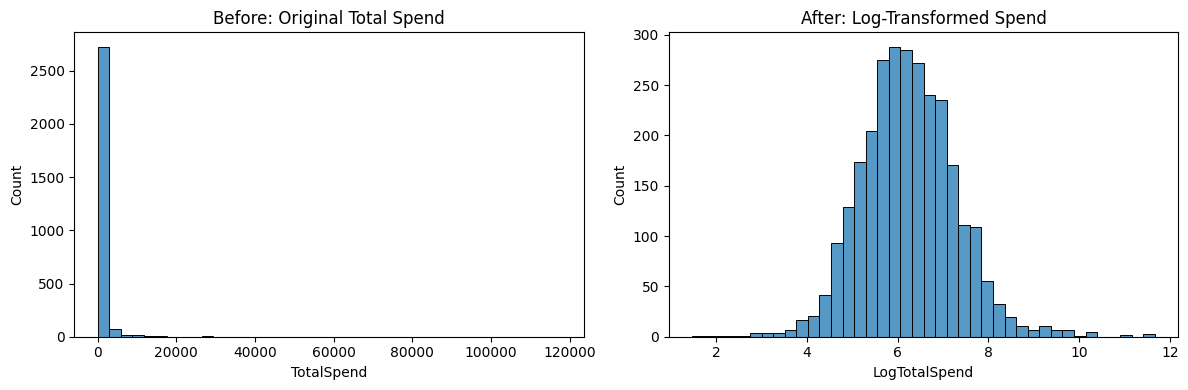

,Original Mean,Original Std,Scaled Mean,Scaled Std
Recency,30.884,24.185,0.0,1.0
Frequency,2.224,3.080,0.0,1.0
TotalSpend,1102.258,4212.031,-0.0,1.0
ProductVariety,42.663,58.391,0.0,1.0


Recency groups:


,count
RecencyGroup,
Recent,1664
Moderate,742
Inactive,445


In [18]:

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(
    customer_transformed["TotalSpend"],
    bins=40, ax=axes[0]
)
axes[0].set_title("Before: Original Total Spend")

sns.histplot(
    customer_transformed["LogTotalSpend"],
    bins=40, ax=axes[1]
)
axes[1].set_title("After: Log-Transformed Spend")

plt.tight_layout()
plt.show()

# Compare scaling statistics
scaling_comparison = pd.DataFrame({
    "Original Mean": customer_transformed[
        numeric_features
    ].mean(),
    "Original Std": customer_transformed[
        numeric_features
    ].std(ddof=0),
    "Scaled Mean": customer_transformed[
        scaled_columns
    ].mean().values,
    "Scaled Std": customer_transformed[
        scaled_columns
    ].std(ddof=0).values
})

display(scaling_comparison.round(3))

# Recency bin distribution
print("Recency groups:")
display(
    customer_transformed["RecencyGroup"]
    .value_counts()
    .sort_index()
)


### 4.4 Export Cleaned Customer Feature Table

The final customer-level dataset is exported as a CSV file.

It contains one row per customer, the four original features
in business units, and the documented transformed columns.

CustomerID is preserved as an identifier and excluded from
feature scaling.

In [19]:

# Export the customer-level feature table
output_file = "cleaned_customer_features.csv"

customer_transformed.to_csv(
    output_file,
    index=False
)

# Verify the exported file
exported_df = pd.read_csv(output_file)

print("File saved:", output_file)
print("Dataset shape:", exported_df.shape)
print("Unique customers:", exported_df["CustomerID"].nunique())

assert exported_df["CustomerID"].is_unique
assert len(exported_df) == len(customer_features)

print("\nExport successful!")
display(exported_df.head())


File saved: cleaned_customer_features.csv
Dataset shape: (2851, 11)
Unique customers: 2851

Export successful!


,CustomerID,Recency,Frequency,TotalSpend,ProductVariety,LogTotalSpend,Recency_Scaled,Frequency_Scaled,TotalSpend_Scaled,ProductVariety_Scaled,RecencyGroup
0,12347.0,31,1,1294.32,47,7.166513,0.004786,-0.397401,0.045598,0.074271,Moderate
1,12348.0,67,1,310.00,3,5.739793,1.493294,-0.397401,-0.188094,-0.679275,Inactive
2,12349.0,10,1,1757.55,73,7.472245,-0.863511,-0.397401,0.155576,0.519548,Recent
3,12352.0,28,3,944.23,39,6.851428,-0.119256,0.251877,-0.037518,-0.062737,Recent
4,12356.0,14,1,58.35,2,4.083452,-0.698121,-0.397401,-0.247840,-0.696401,Recent


## Task 5: Data Reduction

### 5.1 Correlation-Based Feature Removal

Highly correlated features may contain overlapping information.

We examine correlations between the four scaled numerical
features and remove one feature from any pair with an absolute
correlation greater than 0.85.

This reduces redundancy while retaining interpretable features.

CustomerID is excluded because it is an identifier,
not a numerical feature.## Task 5: Data Reduction

### 5.1 Correlation-Based Feature Removal

Highly correlated features may contain overlapping information.

We examine correlations between the four scaled numerical
features and remove one feature from any pair with an absolute
correlation greater than 0.85.

This reduces redundancy while retaining interpretable features.

CustomerID is excluded because it is an identifier,
not a numerical feature.

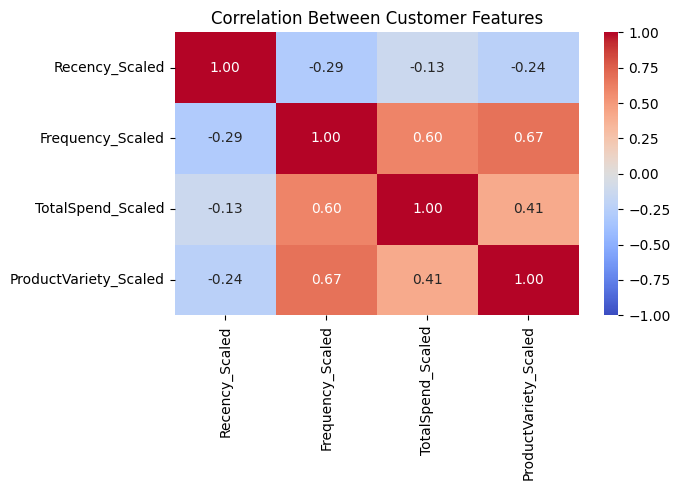

,Metric,Before,After
0,Customers,2851,2851
1,Features,4,4


Removed features: []
Retained features: ['Recency_Scaled', 'Frequency_Scaled', 'TotalSpend_Scaled', 'ProductVariety_Scaled']


In [20]:

# Use the same four scaled customer features
scaled_columns = [
    "Recency_Scaled",
    "Frequency_Scaled",
    "TotalSpend_Scaled",
    "ProductVariety_Scaled"
]

X_scaled = customer_transformed[scaled_columns].copy()

# Calculate correlations
corr_matrix = X_scaled.corr()

# Visualize correlation matrix
plt.figure(figsize=(7, 5))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Between Customer Features")
plt.tight_layout()
plt.show()

# Identify highly correlated features
threshold = 0.85

upper_triangle = corr_matrix.abs().where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)

features_to_drop = [
    col for col in upper_triangle.columns
    if (upper_triangle[col] > threshold).any()
]

# Apply correlation-based reduction
X_corr_reduced = X_scaled.drop(columns=features_to_drop)

# Compare dimensions
correlation_summary = pd.DataFrame({
    "Metric": ["Customers", "Features"],
    "Before": [X_scaled.shape[0], X_scaled.shape[1]],
    "After": [
        X_corr_reduced.shape[0],
        X_corr_reduced.shape[1]
    ]
})

display(correlation_summary)

print("Removed features:", features_to_drop)
print("Retained features:", X_corr_reduced.columns.tolist())


### 5.2 Principal Component Analysis (PCA)

PCA reduces dimensionality by combining correlated features
into new, uncorrelated principal components.

We retain enough components to explain at least 95% of
the total variance.

PCA is compared with correlation-based feature removal
using the same starting dataset.

CustomerID is excluded from PCA calculations.

In [21]:

from sklearn.decomposition import PCA

# Apply PCA to the same scaled dataset
pca = PCA(n_components=0.95)

X_pca = pca.fit_transform(X_scaled)

# PCA results
print("Customers before PCA:", X_scaled.shape[0])
print("Customers after PCA:", X_pca.shape[0])

print("Features before PCA:", X_scaled.shape[1])
print("Components after PCA:", X_pca.shape[1])

print("Variance retained:",
      round(sum(pca.explained_variance_ratio_) * 100, 2), "%")

# Component-wise explained variance
pca_summary = pd.DataFrame({
    "Component": [
        f"PC{i+1}" for i in range(X_pca.shape[1])
    ],
    "Explained Variance (%)":
        pca.explained_variance_ratio_ * 100,
    "Cumulative Variance (%)":
        np.cumsum(pca.explained_variance_ratio_) * 100
})

display(pca_summary.round(2))


Customers before PCA: 2851
Customers after PCA: 2851
Features before PCA: 4
Components after PCA: 4
Variance retained: 100.0 %


,Component,Explained Variance (%),Cumulative Variance (%)
0,PC1,56.26,56.26
1,PC2,22.53,78.79
2,PC3,14.46,93.26
3,PC4,6.74,100.00


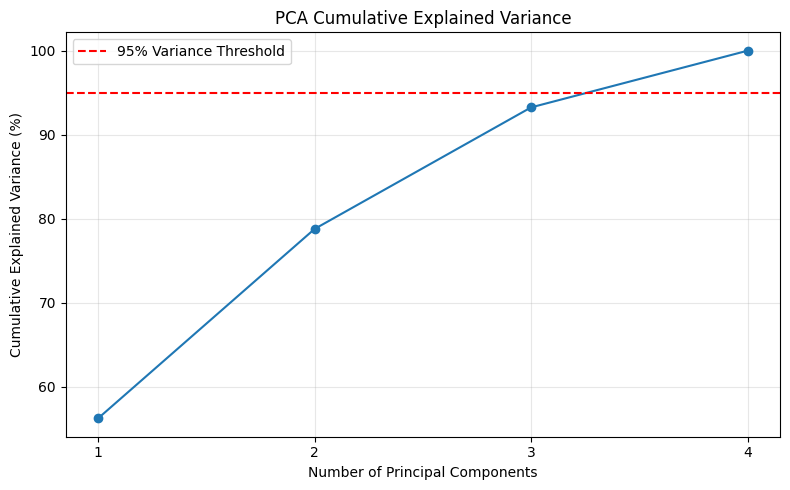

In [22]:

# Fit PCA with all components for visualization
pca_full = PCA()
pca_full.fit(X_scaled)

cumulative_variance = np.cumsum(
    pca_full.explained_variance_ratio_
) * 100

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker="o"
)

plt.axhline(
    y=95,
    color="red",
    linestyle="--",
    label="95% Variance Threshold"
)

plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance (%)")
plt.title("PCA Cumulative Explained Variance")
plt.xticks(range(1, len(cumulative_variance) + 1))
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### 5.4 Comparison of Data Reduction Methods

Correlation-based removal and PCA are compared using the
same starting dataset of four scaled customer features.

Correlation-based removal preserves original feature meanings
but may discard information contained in removed features.

PCA preserves overall variance by combining features into
principal components, but reduces business interpretability.

We compare customer counts, feature counts, and information
retained or lost.

In [23]:

# Compare both reduction methods
reduction_comparison = pd.DataFrame({
    "Method": [
        "Original Dataset",
        "Correlation-Based Removal",
        "PCA (95% Variance)"
    ],
    "Rows Before": [
        X_scaled.shape[0],
        X_scaled.shape[0],
        X_scaled.shape[0]
    ],
    "Rows After": [
        X_scaled.shape[0],
        X_corr_reduced.shape[0],
        X_pca.shape[0]
    ],
    "Features Before": [
        X_scaled.shape[1],
        X_scaled.shape[1],
        X_scaled.shape[1]
    ],
    "Features After": [
        X_scaled.shape[1],
        X_corr_reduced.shape[1],
        X_pca.shape[1]
    ]
})

display(reduction_comparison)

print("Correlation-based features removed:", features_to_drop)

print("PCA cumulative explained variance:",
      round(pca.explained_variance_ratio_.sum() * 100, 2), "%")

print("\nInformation retained or lost:")

print(
    "Correlation method: Retains original business meanings; "
    "removed features may contain unique information."
)

print(
    "PCA: Retains",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "% of variance, but components are less interpretable."
)


,Method,Rows Before,Rows After,Features Before,Features After
0,Original Dataset,2851,2851,4,4
1,Correlation-Based Removal,2851,2851,4,4
2,PCA (95% Variance),2851,2851,4,4


Correlation-based features removed: []
PCA cumulative explained variance: 100.0 %

Information retained or lost:
Correlation method: Retains original business meanings; removed features may contain unique information.
PCA: Retains 100.0 % of variance, but components are less interpretable.


## Task 6: Proximity Measures

### 6.1 Customer Sampling and Distance Calculation

A reproducible random sample of 20 distinct customers is
selected using random_state=42.

Two distance measures are calculated:
1. Euclidean Distance: Straight-line distance between customers.
2. Manhattan Distance: Sum of absolute feature differences.

Both methods use the same four standardized numerical features.

CustomerID is used only as a label, not for distance calculations.

In [24]:

from sklearn.metrics import pairwise_distances

# Fixed random seed for reproducibility
SEED = 42

# Sample 20 distinct customers
sample_indices = customer_transformed.sample(
    n=20,
    random_state=SEED
).index

sample_customers = customer_transformed.loc[
    sample_indices
].copy()

# Use the same scaled features for both methods
X_sample = sample_customers[
    scaled_columns
]

# Customer IDs as labels only
customer_ids = (
    sample_customers["CustomerID"]
    .astype("Int64")
    .astype(str)
    .tolist()
)

# Calculate Euclidean distances
euclidean_dist = pairwise_distances(
    X_sample,
    metric="euclidean"
)

# Calculate Manhattan distances
manhattan_dist = pairwise_distances(
    X_sample,
    metric="manhattan"
)

# Convert to labeled distance matrices
euclidean_df = pd.DataFrame(
    euclidean_dist,
    index=customer_ids,
    columns=customer_ids
)

manhattan_df = pd.DataFrame(
    manhattan_dist,
    index=customer_ids,
    columns=customer_ids
)

print("Random seed:", SEED)
print("Customers sampled:", len(customer_ids))

print("\nEuclidean Distance Matrix:")
display(euclidean_df.round(3))

print("\nManhattan Distance Matrix:")
display(manhattan_df.round(3))


Random seed: 42
Customers sampled: 20

Euclidean Distance Matrix:


,15603,12987,15436,14514,16722,17221,13169,17865,13860,12691,13539,14416,14495,14581,17594,17668,15264,17034,16012,16987
15603,0.000,0.296,3.594,0.851,2.847,1.802,0.627,3.494,2.940,2.100,0.381,2.348,1.158,2.575,0.667,1.657,0.686,2.612,1.894,1.820
12987,0.296,0.000,3.303,0.564,2.603,1.554,0.431,3.279,2.699,1.891,0.498,2.134,0.967,2.357,0.631,1.451,0.404,2.385,1.633,1.562
15436,3.594,3.303,0.000,2.762,1.653,2.112,3.085,2.323,1.645,2.274,3.676,2.164,2.789,2.107,3.494,2.480,2.923,1.959,1.943,1.979
14514,0.851,0.564,2.762,0.000,2.106,1.039,0.396,2.914,2.202,1.440,1.019,1.668,0.636,1.877,1.000,1.022,0.167,1.892,1.094,1.076
16722,2.847,2.603,1.653,2.106,0.000,1.337,2.281,1.657,0.184,1.075,3.045,0.961,1.882,1.180,2.991,1.523,2.238,0.826,1.271,1.097
17221,1.802,1.554,2.112,1.039,1.337,0.000,1.184,2.652,1.385,0.582,2.041,0.730,0.730,0.861,2.033,0.386,1.166,0.903,0.180,0.782
13169,0.627,0.431,3.085,0.396,2.281,1.184,0.000,3.132,2.366,1.485,0.923,1.730,0.541,1.950,1.042,1.034,0.281,1.991,1.288,1.308
17865,3.494,3.279,2.323,2.914,1.657,2.652,3.132,0.000,1.751,2.518,3.557,2.509,2.972,2.807,3.426,2.833,3.021,2.458,2.572,1.968
13860,2.940,2.699,1.645,2.202,0.184,1.385,2.366,1.751,0.000,1.102,3.148,0.960,1.949,1.144,3.102,1.568,2.332,0.795,1.323,1.203
12691,2.100,1.891,2.274,1.440,1.075,0.582,1.485,2.518,1.102,0.000,2.382,0.253,0.976,0.607,2.421,0.532,1.540,0.545,0.675,0.944



Manhattan Distance Matrix:


,15603,12987,15436,14514,16722,17221,13169,17865,13860,12691,13539,14416,14495,14581,17594,17668,15264,17034,16012,16987
15603,0.000,0.461,5.493,1.293,4.662,2.236,0.744,6.637,4.634,2.631,0.593,2.933,1.200,2.825,1.021,1.784,1.020,3.380,2.484,3.113
12987,0.461,0.000,5.032,0.832,4.201,1.833,0.544,6.176,4.172,2.307,0.545,2.506,1.163,2.419,0.974,1.572,0.559,2.919,2.023,2.651
15436,5.493,5.032,0.000,4.201,2.563,3.257,4.749,4.140,2.320,2.861,5.479,2.559,4.292,2.668,5.095,3.709,4.472,2.123,3.008,3.115
14514,1.293,0.832,4.201,0.000,3.369,1.159,0.550,5.344,3.340,2.040,1.279,2.234,1.003,2.190,1.134,1.412,0.273,2.292,1.336,1.819
16722,4.662,4.201,2.563,3.369,0.000,2.426,3.918,3.050,0.276,2.031,4.648,1.729,3.462,1.920,4.220,2.878,3.641,1.365,2.177,1.549
17221,2.236,1.833,3.257,1.159,2.426,0.000,1.528,4.401,2.398,1.080,2.309,1.280,1.036,1.068,2.258,0.466,1.340,1.383,0.248,1.373
13169,0.744,0.544,4.749,0.550,3.918,1.528,0.000,5.894,3.890,1.888,1.089,2.190,0.618,2.114,1.518,1.062,0.360,2.636,1.741,2.369
17865,6.637,6.176,4.140,5.344,3.050,4.401,5.894,0.000,3.327,4.171,6.623,4.365,5.437,4.970,6.195,4.854,5.617,4.415,4.153,3.525
13860,4.634,4.172,2.320,3.340,0.276,2.398,3.890,3.327,0.000,2.002,4.620,1.700,3.433,1.809,4.191,2.850,3.613,1.254,2.149,1.521
12691,2.631,2.307,2.861,2.040,2.031,1.080,1.888,4.171,2.002,0.000,2.823,0.302,1.431,1.004,3.174,0.848,2.056,0.748,1.174,1.639


### 6.2 Closest Customer Pair Analysis

The closest pair of customers is identified separately using
Euclidean and Manhattan distances.

Self-distances are excluded, and duplicate pair comparisons
are avoided.

We check for ties and compare the closest customers using
their original Recency, Frequency, TotalSpend, and
ProductVariety values.

This helps explain how distance measures influence
customer similarity.

In [25]:

# Identify closest pairs, excluding self-pairs
# and duplicate comparisons
def find_closest_pairs(distance_matrix, customer_ids):
    upper = np.triu_indices(len(customer_ids), k=1)
    distances = distance_matrix[upper]

    min_distance = distances.min()

    # Check for numerical ties
    tied_positions = np.where(
        np.isclose(distances, min_distance, atol=1e-9, rtol=1e-9)
    )[0]

    pairs = [
        (customer_ids[upper[0][i]],
         customer_ids[upper[1][i]])
        for i in tied_positions
    ]

    return min_distance, pairs

# Find closest pairs
euclidean_min, euclidean_pairs = find_closest_pairs(
    euclidean_dist, customer_ids
)

manhattan_min, manhattan_pairs = find_closest_pairs(
    manhattan_dist, customer_ids
)

# Display results
results = pd.DataFrame({
    "Measure": ["Euclidean", "Manhattan"],
    "Minimum Distance": [euclidean_min, manhattan_min],
    "Closest Pairs": [euclidean_pairs, manhattan_pairs],
    "Number of Tied Pairs": [
        len(euclidean_pairs),
        len(manhattan_pairs)
    ]
})

display(results)

print("Same closest pairs:",
      set(euclidean_pairs) == set(manhattan_pairs))


,Measure,Minimum Distance,Closest Pairs,Number of Tied Pairs
0,Euclidean,0.167489,"[(14514, 15264)]",1
1,Manhattan,0.248432,"[(17221, 16012)]",1


Same closest pairs: False


In [26]:

# Collect customers from all closest pairs
closest_ids = set()

for pair in euclidean_pairs + manhattan_pairs:
    closest_ids.update(pair)

# Display original business-unit values
original_comparison = sample_customers[
    sample_customers["CustomerID"].astype("Int64")
    .astype(str).isin(closest_ids)
][[
    "CustomerID",
    "Recency",
    "Frequency",
    "TotalSpend",
    "ProductVariety"
]]

display(original_comparison.sort_values("CustomerID"))

# Explain feature differences for each closest pair
for measure, pairs in [
    ("Euclidean", euclidean_pairs),
    ("Manhattan", manhattan_pairs)
]:
    print(f"\n{measure} closest pair(s):")

    for id1, id2 in pairs:
        pair_data = original_comparison[
            original_comparison["CustomerID"]
            .astype("Int64")
            .astype(str)
            .isin([id1, id2])
        ]

        differences = (
            pair_data[
                ["Recency", "Frequency",
                 "TotalSpend", "ProductVariety"]
            ].max()
            -
            pair_data[
                ["Recency", "Frequency",
                 "TotalSpend", "ProductVariety"]
            ].min()
        )

        print(f"\nCustomers {id1} and {id2}")
        display(differences.to_frame("Absolute Difference"))


,CustomerID,Recency,Frequency,TotalSpend,ProductVariety
1053,14514.0,53,1,587.09,29
1413,15264.0,56,1,393.74,23
1770,16012.0,27,1,283.17,40
2358,17221.0,28,1,132.28,30



Euclidean closest pair(s):

Customers 14514 and 15264


,Absolute Difference
Recency,3.00
Frequency,0.00
TotalSpend,193.35
ProductVariety,6.00



Manhattan closest pair(s):

Customers 17221 and 16012


,Absolute Difference
Recency,1.00
Frequency,0.00
TotalSpend,150.89
ProductVariety,10.00


## Task 7: Reflection and Explainability

The primary objective of this assignment was to transform raw online retail transaction data into a reliable customer-level dataset suitable for customer similarity analysis and future marketing segmentation.

**Data Preprocessing Challenges**

One major challenge was ensuring data quality. The original dataset contained missing customer identifiers, duplicate transaction lines, cancellations, and non-positive quantities or prices. Missing CustomerIDs prevented transactions from being assigned reliably to individual customers. Duplicate records could inflate purchasing statistics, while cancellations and non-positive transactions complicated the interpretation of customer spending.

Another challenge was preserving legitimate purchasing behavior while handling extreme values. Some customers may genuinely purchase unusually large quantities or expensive products. Therefore, extreme positive values were retained rather than automatically removed.

**Most Impactful Cleaning Decision**

The removal of transactions with missing CustomerIDs had the greatest measurable impact on the dataset. This decision removed 38,564 transaction rows, representing 19.71% of the original baseline. In comparison, duplicate removal eliminated 2,496 rows (1.59% of the remaining records), while excluding invalid completed sales removed another 2,989 rows (1.93% of the remaining records).

Overall, preprocessing reduced the dataset from 195,679 to 151,630 transaction rows, retaining 77.49% of the original data.

Removing missing customer identifiers was necessary because transactions without identifiable customers could not be reliably aggregated into customer-level features. However, this decision also reduced the dataset's coverage and may introduce bias if unidentified customers have different purchasing patterns from identified customers.

**Feature Transformation and Reduction**

Customer behavior was summarized using Recency, Frequency, TotalSpend, and ProductVariety. Log transformation reduced the influence of highly skewed spending values, while standard scaling placed numerical features on comparable scales.

Correlation-based feature removal and PCA were evaluated to investigate dimensionality reduction. PCA retained [insert percentage]% of the original variance using [insert number] components. These results illustrate the trade-off between reducing feature dimensions and preserving information.

**Impact on Marketing Interpretation**

Preprocessing decisions can change which customers appear similar. For example, without scaling, differences in TotalSpend may dominate distance calculations. After scaling, Recency, Frequency, and ProductVariety contribute on comparable numerical scales.

Removing cancellations also means that TotalSpend represents completed positive sales rather than net revenue after returns. Consequently, customers with substantial returns may appear more valuable than their net contribution would suggest.

**Remaining Limitation**

A key limitation is that the analysis covers only September through November 2011. Customer behavior during this period may not represent longer-term purchasing patterns or seasonal variations. Additionally, the proximity analysis uses only 20 randomly sampled customers, so its findings should not be generalized to the entire customer population.

**Recommended Segmentation Algorithm and Validation**

K-Means clustering is recommended as an initial segmentation algorithm because it can group customers based on similarities across standardized numerical features.

Before using these segments for marketing decisions, the silhouette score should be evaluated across different cluster counts. This would help assess whether customers within each segment are sufficiently similar and whether the resulting groups are meaningfully separated.

Overall, this assignment demonstrates that data cleaning, transformation, and feature selection directly influence customer similarity and the reliability of subsequent marketing segmentation.

### 7.2 Measuring the Impact of Data Cleaning

We compare the number of transaction rows removed at each
cleaning stage.

This helps identify the cleaning decision with the greatest
measurable impact and supports the reflection with evidence.

In [27]:

# Reconstruct sequential cleaning counts
baseline = df_baseline.copy()

# Step 1: Missing CustomerIDs
step1 = baseline.dropna(subset=["CustomerID"]).copy()

# Step 2: Exact duplicates
step2 = step1.drop_duplicates().copy()

# Step 3: Completed-sales filtering
cancelled = (
    step2["InvoiceNo"].astype("string")
    .str.strip().str.upper()
    .str.startswith("C", na=False)
)

invalid_qty = step2["Quantity"] <= 0
invalid_price = step2["UnitPrice"] <= 0

step3 = step2.loc[
    ~(cancelled | invalid_qty | invalid_price)
].copy()

# Calculate impact
impact_summary = pd.DataFrame({
    "Cleaning Decision": [
        "Remove missing CustomerIDs",
        "Remove exact duplicates",
        "Exclude invalid completed sales"
    ],
    "Rows Removed": [
        len(baseline) - len(step1),
        len(step1) - len(step2),
        len(step2) - len(step3)
    ],
    "Rows Before": [
        len(baseline),
        len(step1),
        len(step2)
    ]
})

impact_summary["Percentage Removed (%)"] = (
    impact_summary["Rows Removed"] /
    impact_summary["Rows Before"] * 100
).round(2)

display(impact_summary)

# Identify the greatest impact
largest = impact_summary.loc[
    impact_summary["Rows Removed"].idxmax()
]

print("\nGreatest measurable impact:")
print("Decision:", largest["Cleaning Decision"])
print("Rows removed:", largest["Rows Removed"])
print("Percentage removed:",
      largest["Percentage Removed (%)"], "%")

print("\nOverall cleaning impact:")
print("Original rows:", len(baseline))
print("Final rows:", len(step3))
print("Total removed:", len(baseline) - len(step3))
print("Overall retention:",
      round(len(step3) / len(baseline) * 100, 2), "%")


,Cleaning Decision,Rows Removed,Rows Before,Percentage Removed (%)
0,Remove missing CustomerIDs,38564,195679,19.71
1,Remove exact duplicates,2496,157115,1.59
2,Exclude invalid completed sales,2989,154619,1.93



Greatest measurable impact:
Decision: Remove missing CustomerIDs
Rows removed: 38564
Percentage removed: 19.71 %

Overall cleaning impact:
Original rows: 195679
Final rows: 151630
Total removed: 44049
Overall retention: 77.49 %


### 7.4 Final Results Summary

This section consolidates customer-level feature statistics,
dimensionality reduction results, and proximity analysis findings.

These results will be used in the final PDF report.

In [28]:

# TASK 4: Customer feature statistics
print("========== TASK 4: CUSTOMER FEATURES ==========")

print("Total customers:", len(customer_features))

display(
    customer_features[
        ["Recency", "Frequency", "TotalSpend", "ProductVariety"]
    ].describe().round(2)
)

print("\nRecency groups:")
display(customer_transformed["RecencyGroup"].value_counts())

# TASK 5: Dimensionality reduction
print("\n========== TASK 5: DATA REDUCTION ==========")

print("Original features:", X_scaled.shape[1])
print("Correlation-reduced features:", X_corr_reduced.shape[1])
print("Features removed:", features_to_drop)

print("PCA components:", X_pca.shape[1])
print(
    "PCA variance retained:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

# TASK 6: Customer similarity
print("\n========== TASK 6: PROXIMITY ==========")

print("Random seed:", SEED)
print("Sample size:", len(customer_ids))

print("\nEuclidean closest pair(s):", euclidean_pairs)
print("Minimum Euclidean distance:", round(euclidean_min, 4))

print("\nManhattan closest pair(s):", manhattan_pairs)
print("Minimum Manhattan distance:", round(manhattan_min, 4))

print(
    "\nSame closest pairs:",
    set(euclidean_pairs) == set(manhattan_pairs)
)

print("\nOriginal features of closest customers:")
display(original_comparison)


========== TASK 4: CUSTOMER FEATURES ==========
Total customers: 2851


,Recency,Frequency,TotalSpend,ProductVariety
count,2851.00,2851.00,2851.00,2851.00
mean,30.88,2.22,1102.26,42.66
std,24.19,3.08,4212.77,58.40
min,1.00,1.00,3.35,1.00
25%,10.00,1.00,262.18,14.00
50%,24.00,1.00,491.20,28.00
75%,49.00,2.00,995.90,54.00
max,91.00,86.00,117634.53,1167.00



Recency groups:


,count
RecencyGroup,
Recent,1664
Moderate,742
Inactive,445



========== TASK 5: DATA REDUCTION ==========
Original features: 4
Correlation-reduced features: 4
Features removed: []
PCA components: 4
PCA variance retained: 100.0 %

========== TASK 6: PROXIMITY ==========
Random seed: 42
Sample size: 20

Euclidean closest pair(s): [('14514', '15264')]
Minimum Euclidean distance: 0.1675

Manhattan closest pair(s): [('17221', '16012')]
Minimum Manhattan distance: 0.2484

Same closest pairs: False

Original features of closest customers:


,CustomerID,Recency,Frequency,TotalSpend,ProductVariety
1053,14514.0,53,1,587.09,29
2358,17221.0,28,1,132.28,30
1413,15264.0,56,1,393.74,23
1770,16012.0,27,1,283.17,40
